In [1]:
# ============================================================================
# MSGR-RAG Component 1: Data Loading & Availability Check
# ============================================================================
# Purpose: Validate DrugBank data and select 100 drugs for knowledge graph
# Author: Pavan Kumar Reddy Yannam
# Date: December 2024
# ============================================================================

In [2]:
# # Component 1: DrugBank Data Exploration
# 
# **Objectives:**
# 1. Load DrugBank dataset and verify data quality
# 2. Analyze availability of relationship data (treats, interacts_with, causes)
# 3. Select 100 drugs with therapeutic diversity
# 4. Assess feasibility of concept and domain mapping
# 5. Generate data availability report

In [3]:
import pandas as pd
import numpy as np
import json
import warnings
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.width', None)
warnings.filterwarnings('ignore')

In [5]:
plt.style.use('default')
sns.set_palette("husl")

In [6]:
print("✓ Libraries imported successfully")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

✓ Libraries imported successfully
Pandas version: 2.2.2
NumPy version: 1.26.4


In [11]:
DATA_DIR = Path("../Datasets")
DRUGBANK_PATH = DATA_DIR / "drugbank_clean.csv"
OUTPUT_DIR = DATA_DIR / "intermediate"

In [12]:
# Create output directory if it doesn't exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [13]:
print(f"✓ Data directory: {DATA_DIR}")
print(f"✓ DrugBank file: {DRUGBANK_PATH}")
print(f"✓ Output directory: {OUTPUT_DIR}")

✓ Data directory: ../Datasets
✓ DrugBank file: ../Datasets/drugbank_clean.csv
✓ Output directory: ../Datasets/intermediate


In [14]:
# Verify file exists
if DRUGBANK_PATH.exists():
    print(f"✓ DrugBank file found: {DRUGBANK_PATH}")
else:
    print(f"✗ ERROR: DrugBank file not found at {DRUGBANK_PATH}")
    print("Please update DRUGBANK_PATH variable with correct path")

✓ DrugBank file found: ../Datasets/drugbank_clean.csv


In [15]:
# ## Section 2: Load DrugBank Dataset

In [19]:
print("Loading DrugBank dataset...")
print("=" * 80)
# Load data
drugbank_df = pd.read_csv(DRUGBANK_PATH, low_memory=False)

Loading DrugBank dataset...


In [20]:
# Drop completely empty rows
drugbank_df = drugbank_df.dropna(how='all')

In [21]:
print(f"✓ Dataset loaded successfully")
print(f"\nDataset Shape: {drugbank_df.shape}")
print(f"  - Total Drugs: {len(drugbank_df):,}")
print(f"  - Total Columns: {len(drugbank_df.columns)}")

✓ Dataset loaded successfully

Dataset Shape: (16761, 40)
  - Total Drugs: 16,761
  - Total Columns: 40


In [22]:
# Display column names
print("\nAvailable Columns:")
print("=" * 80)
for i, col in enumerate(drugbank_df.columns, 1):
    print(f"{i:2d}. {col}")


Available Columns:
 1. type
 2. created
 3. updated
 4. drugbank-id
 5. name
 6. description
 7. cas-number
 8. unii
 9. state
10. groups
11. synthesis-reference
12. indication
13. pharmacodynamics
14. mechanism-of-action
15. toxicity
16. metabolism
17. absorption
18. half-life
19. protein-binding
20. route-of-elimination
21. volume-of-distribution
22. clearance
23. atc-codes
24. ahfs-codes
25. pdb-entries
26. food-interactions
27. drug-interactions
28. sequences
29. enzymes
30. pathways
31. reactions
32. snp-effects
33. snp-adverse-drug-reactions
34. targets
35. carriers
36. transporters
37. fda-label
38. msds
39. average-mass
40. monoisotopic-mass


In [23]:
# Display first few rows
print("\nFirst 3 Rows (Preview):")
print("=" * 80)
drugbank_df.head(3)


First 3 Rows (Preview):


,type,created,updated,drugbank-id,name,description,cas-number,unii,state,groups,synthesis-reference,indication,pharmacodynamics,mechanism-of-action,toxicity,metabolism,absorption,half-life,protein-binding,route-of-elimination,volume-of-distribution,clearance,atc-codes,ahfs-codes,pdb-entries,food-interactions,drug-interactions,sequences,enzymes,pathways,reactions,snp-effects,snp-adverse-drug-reactions,targets,carriers,transporters,fda-label,msds,average-mass,monoisotopic-mass
0,biotech,2005-06-13,2023-01-03,DB00001,Lepirudin,Lepirudin is a recombinant hirudin formed by 65 amino acids that acts as a highly specific and d...,138068-37-8,Y43GF64R34,solid,approved withdrawn,"Recombinant hirudin expressed by using yeast secretary (China Patent No. CN1371994A, 2001). Chin...",Lepirudin is indicated for anticoagulation in adult patients with acute coronary syndromes (ACS)...,Lepirudin is a recombinant hirudin that acts as a highly specific thrombin inhibitor. Its activi...,Lepirudin is a direct thrombin inhibitor used as an anticoagulant in patients for whom heparin i...,"The acute toxicity of intravenous lepirudin was evaluated in mice (0.1-1000 mg/kg), rats (1-1000...","As a polypeptide, lepirudin is expected to be metabolized by the sequential cleavage of amino ac...",Lepirudin administered as a single intravenous bolus injection of 0.4 mg/kg in 9 healthy volunte...,"Lepirudin has an initial half-life of approximately 10 minutes, and in young healthy volunteers,...","In human plasma, the protein binding of lepirudin was approximately 3%.[L41539]",Lepirudin is mostly excreted through urine (48.3%). About 35% of lepirudin is excreted unchanged...,The volume of distribution of lepirudin at steady state was 12.2 L in healthy young subjects (n=...,"The clearance of lepirudin is proportional to the glomerular filtration rate. On average, lepiru...",BLOOD AND BLOOD FORMING ORGANS ANTITHROMBOTIC AGENTS Direct thrombin inhibitors,NaN,NaN,Avoid herbs and supplements with anticoagulant/antiplatelet activity. Examples include chamomile...,DB13821 DB00328 DB08953 DB00682 DB00928 DB09124 DB13400 DB09381 DB00656 DB09052 DB06679 DB06737 ...,>DB00001 sequence\nLTYTDCTESGQNLCLCEGSNVCGQGNKCILGSDGEKNQCVTGEGTPKPQSHNDGDFEEIP\nEEYLQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,P00488 P00748 P38435 Q9BQB6 P00734 P08709 P03952 P00451 P13726 P00742 P03951 P00740 P00747 P0267...,NaN,NaN,NaN,BE0000048,NaN,NaN,NaN,NaN,NaN,NaN
3,biotech,2005-06-13,2023-01-03,DB00002,Cetuximab,Cetuximab is a recombinant chimeric human/mouse IgG1 monoclonal antibody that competitively bind...,205923-56-4,PQX0D8J21J,liquid,approved,NaN,Cetuximab indicated for the treatment of locally or regionally advanced squamous cell carcinoma ...,Cetuximab is an anticancer agent that works by inhibiting the growth and survival of epidermal g...,The epidermal growth factor receptor (EGFR) is a transmembrane glycoprotein and a type I recepto...,The intravenous LD<sub>50</sub> is > 300 mg/kg in mice and > 200 mg/kg in rats.[L31408] There is...,"Like other monoclonal antibodies, cetuximab is expected to undergo lysosomal degradation by the ...",After administration of a 400 mg/m<sup>2</sup> initial dose followed by a 250 mg/m<sup>2</sup> w...,After administration of a 400 mg/m<sup>2</sup> initial dose followed by a 250 mg/m<sup>2</sup> w...,There is no information available.,There is limited information available.,The volume of the distribution is about 2-3 L/m<sup>2</sup> and is independent of dose.[L30448],"In patients with recurrent and/or metastatic squamous cell carcinoma of the head and neck, the e...",ANTINEOPLASTIC AND IMMUNOMODULATING AGENTS MONOCLONAL ANTIBODIES AND ANTIBODY DRUG CONJUGATES AN...,NaN,NaN,NaN,DB05209 DB14905 DB06474 DB09381 DB06647 DB11959 DB09052 DB13259 DB12034 DB11857 DB14039 DB12023 ...,>Cetuximab light chain\nDILLTQSPVILSVSPGERVSFSCRASQSIGTNIHWYQQR

In [24]:
# Data types
print("\nColumn Data Types:")
print("=" * 80)
print(drugbank_df.dtypes)


Column Data Types:
type                           object
created                        object
updated                        object
drugbank-id                    object
name                           object
description                    object
cas-number                     object
unii                           object
state                          object
groups                         object
synthesis-reference            object
indication                     object
pharmacodynamics               object
mechanism-of-action            object
toxicity                       object
metabolism                     object
absorption                     object
half-life                      object
protein-binding                object
route-of-elimination           object
volume-of-distribution         object
clearance                      object
atc-codes                      object
ahfs-codes                    float64
pdb-entries                    object
food-interactions             

In [25]:
# Memory usage
print("\nMemory Usage:")
print("=" * 80)
memory_usage = drugbank_df.memory_usage(deep=True)
print(f"Total: {memory_usage.sum() / 1024**2:.2f} MB")
print("\nTop 10 memory-intensive columns:")
print(memory_usage.sort_values(ascending=False).head(10).apply(lambda x: f"{x/1024**2:.2f} MB"))



Memory Usage:
Total: 63.46 MB

Top 10 memory-intensive columns:
drug-interactions      22.45 MB
description             4.53 MB
mechanism-of-action     3.92 MB
pharmacodynamics        2.62 MB
toxicity                1.90 MB
pdb-entries             1.86 MB
indication              1.66 MB
absorption              1.48 MB
metabolism              1.27 MB
name                    1.16 MB
dtype: object


In [26]:
# ## Section 3: Data Availability Analysis
# 
# **Key Columns for MSGR-RAG:**
# - `drug-interactions` → for 'interacts_with' relationship
# - `toxicity` → for 'causes' relationship
# - `description` / `indication` → for 'treats' relationship
# - `categories` → for concept-level mapping
# - Any domain/specialty fields → for domain-level mapping

In [27]:
# Identify key columns for our relationships
key_columns = {
    'identity': ['drugbank-id', 'name'],
    'classification': ['groups', 'categories'],
    'relationships': ['drug-interactions', 'toxicity', 'food-interactions', 
                     'snp-adverse-drug-reactions'],
    'therapeutic': ['description', 'indication']  # May not be in dataset
}

In [28]:
print("Checking availability of key columns:")
print("=" * 80)

available_columns = {}
for category, cols in key_columns.items():
    available_columns[category] = []
    print(f"\n{category.upper()}:")
    for col in cols:
        if col in drugbank_df.columns:
            print(f"  ✓ {col}")
            available_columns[category].append(col)
        else:
            print(f"  ✗ {col} (NOT FOUND)")

Checking availability of key columns:

IDENTITY:
  ✓ drugbank-id
  ✓ name

CLASSIFICATION:
  ✓ groups
  ✗ categories (NOT FOUND)

RELATIONSHIPS:
  ✓ drug-interactions
  ✓ toxicity
  ✓ food-interactions
  ✓ snp-adverse-drug-reactions

THERAPEUTIC:
  ✓ description
  ✓ indication


In [30]:
# Data completeness analysis
print("\nData Completeness Analysis:")
print("=" * 80)

completeness_stats = {}

for col in drugbank_df.columns:
    non_null = drugbank_df[col].notna().sum()
    total = len(drugbank_df)
    percentage = (non_null / total) * 100
    
    completeness_stats[col] = {
        'non_null_count': int(non_null),
        'total_count': int(total),
        'completeness_pct': round(percentage, 2)
    }


Data Completeness Analysis:


In [31]:
# Create DataFrame for better visualization
completeness_df = pd.DataFrame(completeness_stats).T
completeness_df = completeness_df.sort_values('completeness_pct', ascending=False)

In [32]:
print("\nTop 15 Most Complete Columns:")
print(completeness_df.head(15))


Top 15 Most Complete Columns:
                   non_null_count  total_count  completeness_pct
drugbank-id               16166.0      16761.0             96.45
name                      16166.0      16761.0             96.45
type                      15235.0      16761.0             90.90
groups                    15235.0      16761.0             90.90
updated                   15235.0      16761.0             90.90
created                   15235.0      16761.0             90.90
description               12929.0      16761.0             77.14
average-mass              11586.0      16761.0             69.12
monoisotopic-mass         11586.0      16761.0             69.12
unii                      10934.0      16761.0             65.23
cas-number                 9553.0      16761.0             57.00
state                      9171.0      16761.0             54.72
targets                    7867.0      16761.0             46.94
pdb-entries                5940.0      16761.0             

In [33]:
print("\n\nKey Columns for MSGR-RAG:")
key_relationship_cols = ['drug-interactions', 'toxicity', 'food-interactions', 
                         'snp-adverse-drug-reactions']
for col in key_relationship_cols:
    if col in completeness_df.index:
        stats = completeness_df.loc[col]
        print(f"\n{col}:")
        print(f"  Non-null: {stats['non_null_count']:,} / {stats['total_count']:,}")
        print(f"  Completeness: {stats['completeness_pct']:.1f}%")



Key Columns for MSGR-RAG:

drug-interactions:
  Non-null: 4,478.0 / 16,761.0
  Completeness: 26.7%

toxicity:
  Non-null: 2,432.0 / 16,761.0
  Completeness: 14.5%

food-interactions:
  Non-null: 1,378.0 / 16,761.0
  Completeness: 8.2%

snp-adverse-drug-reactions:
  Non-null: 45.0 / 16,761.0
  Completeness: 0.3%



Generating completeness visualization...


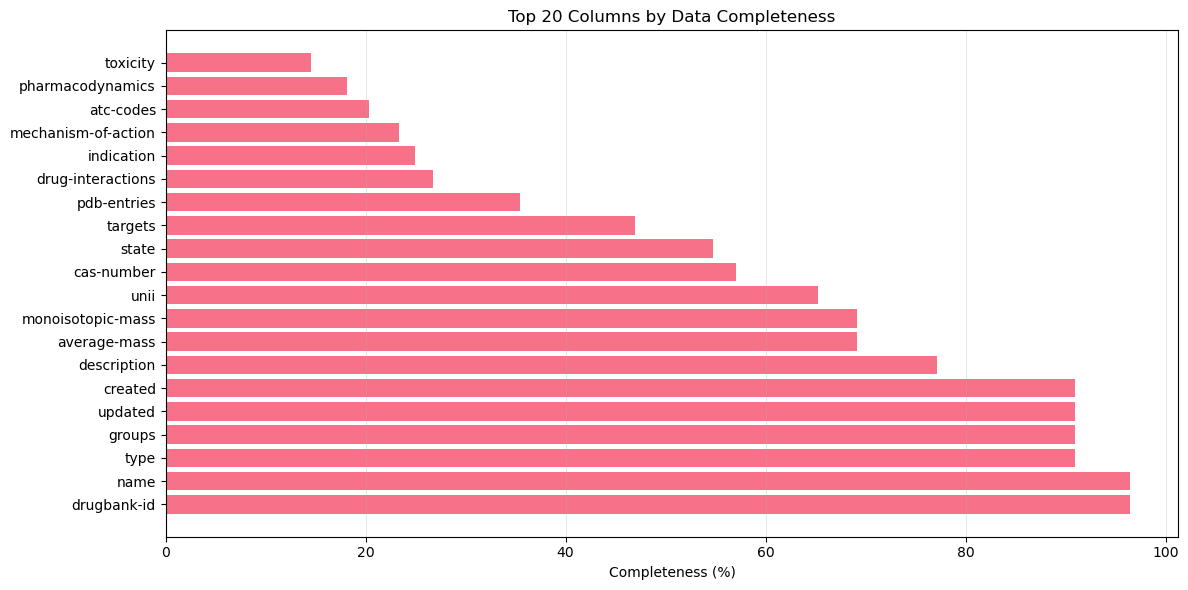

In [34]:
# Visualize data completeness
print("\nGenerating completeness visualization...")

fig, ax = plt.subplots(figsize=(12, 6))
top_cols = completeness_df.head(20)
ax.barh(range(len(top_cols)), top_cols['completeness_pct'])
ax.set_yticks(range(len(top_cols)))
ax.set_yticklabels(top_cols.index)
ax.set_xlabel('Completeness (%)')
ax.set_title('Top 20 Columns by Data Completeness')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'data_completeness.png', dpi=300, bbox_inches='tight')
plt.show()

In [35]:
print(f"✓ Visualization saved to {OUTPUT_DIR / 'data_completeness.png'}")

✓ Visualization saved to ../Datasets/intermediate/data_completeness.png


In [37]:
print("Analyzing Relationship Extraction Feasibility:")
print("=" * 80)

relationship_feasibility = {}

# ============================================================================
# 1. INTERACTS_WITH Relationship
# ============================================================================
print("\n1. 'interacts_with' Relationship (from drug-interactions)")
print("-" * 80)

if 'drug-interactions' in drugbank_df.columns:
    interactions_col = drugbank_df['drug-interactions']
    
    # Count drugs with interaction data
    drugs_with_interactions = interactions_col.notna().sum()
    
    # Estimate number of interactions (assuming delimiter like '|' or ';')
    # We'll sample a few to understand the format
    sample_interactions = interactions_col.dropna().head(10)
    
    print(f"Drugs with interaction data: {drugs_with_interactions:,} / {len(drugbank_df):,}")
    print(f"Percentage: {(drugs_with_interactions/len(drugbank_df)*100):.1f}%")
    
    print("\nSample interaction entries:")
    for idx, interaction in enumerate(sample_interactions.iloc[:3], 1):
        print(f"\n  Sample {idx}:")
        preview = str(interaction)[:200] + "..." if len(str(interaction)) > 200 else str(interaction)
        print(f"  {preview}")
    
    relationship_feasibility['interacts_with'] = {
        'extractable_from': ['drug-interactions'],
        'drugs_with_data': int(drugs_with_interactions),
        'percentage': round((drugs_with_interactions/len(drugbank_df)*100), 2),
        'confidence': 'high' if drugs_with_interactions > 1000 else 'medium'
    }
else:
    print("✗ 'drug-interactions' column not found")
    relationship_feasibility['interacts_with'] = {
        'extractable_from': [],
        'drugs_with_data': 0,
        'percentage': 0,
        'confidence': 'low'
    }

# ============================================================================
# 2. CAUSES Relationship
# ============================================================================
print("\n\n2. 'causes' Relationship (from toxicity)")
print("-" * 80)

if 'toxicity' in drugbank_df.columns:
    toxicity_col = drugbank_df['toxicity']
    
    # Count drugs with toxicity data
    drugs_with_toxicity = toxicity_col.notna().sum()
    
    print(f"Drugs with toxicity data: {drugs_with_toxicity:,} / {len(drugbank_df):,}")
    print(f"Percentage: {(drugs_with_toxicity/len(drugbank_df)*100):.1f}%")
    
    # Sample toxicity entries
    sample_toxicity = toxicity_col.dropna().head(10)
    
    print("\nSample toxicity entries:")
    for idx, tox in enumerate(sample_toxicity.iloc[:3], 1):
        print(f"\n  Sample {idx}:")
        preview = str(tox)[:200] + "..." if len(str(tox)) > 200 else str(tox)
        print(f"  {preview}")
    
    # Count common toxicity keywords
    toxicity_keywords = ['hepatotoxic', 'nephrotoxic', 'cardiotoxic', 'neurotoxic',
                         'LD50', 'carcinogen', 'teratogenic', 'adverse', 'toxic']
    
    print("\nToxicity keyword frequency:")
    keyword_counts = {}
    for keyword in toxicity_keywords:
        count = toxicity_col.astype(str).str.contains(keyword, case=False, na=False).sum()
        keyword_counts[keyword] = count
        if count > 0:
            print(f"  {keyword}: {count}")
    
    relationship_feasibility['causes'] = {
        'extractable_from': ['toxicity', 'snp-adverse-drug-reactions'],
        'drugs_with_data': int(drugs_with_toxicity),
        'percentage': round((drugs_with_toxicity/len(drugbank_df)*100), 2),
        'keyword_matches': keyword_counts,
        'confidence': 'high' if drugs_with_toxicity > 1000 else 'medium'
    }
else:
    print("✗ 'toxicity' column not found")
    relationship_feasibility['causes'] = {
        'extractable_from': [],
        'drugs_with_data': 0,
        'percentage': 0,
        'confidence': 'low'
    }

# ============================================================================
# 3. TREATS Relationship
# ============================================================================
print("\n\n3. 'treats' Relationship (from description/indication/categories)")
print("-" * 80)

treats_sources = []
treats_counts = {}

# Check each potential source
for col in ['description', 'indication', 'categories']:
    if col in drugbank_df.columns:
        treats_sources.append(col)
        non_null = drugbank_df[col].notna().sum()
        treats_counts[col] = int(non_null)
        print(f"✓ {col}: {non_null:,} drugs ({(non_null/len(drugbank_df)*100):.1f}%)")
        
        # Sample entries
        if non_null > 0:
            sample = drugbank_df[col].dropna().head(3)
            print(f"\n  Sample {col} entries:")
            for idx, entry in enumerate(sample, 1):
                preview = str(entry)[:150] + "..." if len(str(entry)) > 150 else str(entry)
                print(f"    {idx}. {preview}")
            print()
    else:
        print(f"✗ {col}: not found")

if treats_sources:
    total_with_treats_data = drugbank_df[treats_sources].notna().any(axis=1).sum()
    relationship_feasibility['treats'] = {
        'extractable_from': treats_sources,
        'drugs_with_data': int(total_with_treats_data),
        'percentage': round((total_with_treats_data/len(drugbank_df)*100), 2),
        'source_counts': treats_counts,
        'confidence': 'medium' if total_with_treats_data > 500 else 'low'
    }
else:
    relationship_feasibility['treats'] = {
        'extractable_from': [],
        'drugs_with_data': 0,
        'percentage': 0,
        'confidence': 'low'
    }

print(f"\nTotal drugs with ANY treats-related data: {total_with_treats_data:,}")

# %%
# Summary of relationship feasibility
print("\n" + "=" * 80)
print("RELATIONSHIP EXTRACTION FEASIBILITY SUMMARY")
print("=" * 80)

for rel_type, data in relationship_feasibility.items():
    print(f"\n{rel_type.upper()}:")
    print(f"  Sources: {', '.join(data['extractable_from']) if data['extractable_from'] else 'None'}")
    print(f"  Drugs with data: {data['drugs_with_data']:,}")
    print(f"  Coverage: {data['percentage']:.1f}%")
    print(f"  Confidence: {data['confidence'].upper()}")

Analyzing Relationship Extraction Feasibility:

1. 'interacts_with' Relationship (from drug-interactions)
--------------------------------------------------------------------------------
Drugs with interaction data: 4,478 / 16,761
Percentage: 26.7%

Sample interaction entries:

  Sample 1:
  DB13821 DB00328 DB08953 DB00682 DB00928 DB09124 DB13400 DB09381 DB00656 DB09052 DB06679 DB06737 DB03374 DB08814 DB12289 DB06251 DB09217 DB11133 DB00970 DB01066 DB13875 DB13876 DB00034 DB00814 DB00562 ...

  Sample 2:
  DB05209 DB14905 DB06474 DB09381 DB06647 DB11959 DB09052 DB13259 DB12034 DB11857 DB14039 DB12023 DB06305 DB15898 DB14877 DB00814 DB11604 DB12344 DB13886 DB05232 DB14811 DB11884 DB11685 DB11746 DB15118 ...

  Sample 3:
  DB06770 DB12532 DB00281 DB09107 DB08987 DB00296 DB13259 DB00297 DB13578 DB13683 DB00016 DB01161 DB00961 DB00807 DB11148 DB00907 DB01075 DB00814 DB06774 DB00527 DB00645 DB09345 DB13328 DB09009 DB00721 ...


2. 'causes' Relationship (from toxicity)
----------------------

In [38]:
# ## Section 5: Therapeutic Categorization
# 
# Goal: Categorize drugs into 10 therapeutic areas for diversity

In [39]:
print("Analyzing Therapeutic Categorization:")
print("=" * 80)

# Check if 'groups' or 'categories' columns exist
categorization_sources = []

if 'groups' in drugbank_df.columns:
    categorization_sources.append('groups')
    print("\n✓ 'groups' column found")
    print(f"  Unique values: {drugbank_df['groups'].nunique()}")
    print(f"  Sample values:")
    print(drugbank_df['groups'].value_counts().head(10))

if 'categories' in drugbank_df.columns:
    categorization_sources.append('categories')
    print("\n✓ 'categories' column found")
    non_null_categories = drugbank_df['categories'].notna().sum()
    print(f"  Non-null entries: {non_null_categories:,} ({(non_null_categories/len(drugbank_df)*100):.1f}%)")
    
    # Sample categories
    if non_null_categories > 0:
        sample_cats = drugbank_df['categories'].dropna().head(5)
        print(f"  Sample entries:")
        for idx, cat in enumerate(sample_cats, 1):
            preview = str(cat)[:150] + "..." if len(str(cat)) > 150 else str(cat)
            print(f"    {idx}. {preview}")

# %%
# Define our target therapeutic areas
target_therapeutic_areas = {
    'Cardiovascular': ['cardiovascular', 'cardiac', 'heart', 'antihypertensive', 
                       'anticoagulant', 'antiplatelet', 'statin'],
    'Endocrine': ['diabetes', 'insulin', 'thyroid', 'hormone', 'endocrine',
                  'antidiabetic', 'glucagon'],
    'Neurological': ['neurological', 'neural', 'brain', 'anticonvulsant', 
                     'antiepileptic', 'parkinsons', 'alzheimer'],
    'Anti-inflammatory': ['anti-inflammatory', 'nsaid', 'corticosteroid', 
                          'inflammatory', 'arthritis'],
    'Antibiotics': ['antibiotic', 'antibacterial', 'antimicrobial', 'antiviral',
                    'antifungal', 'antiparasitic'],
    'Gastrointestinal': ['gastrointestinal', 'gastric', 'antacid', 'laxative',
                         'antiemetic', 'digestive'],
    'Respiratory': ['respiratory', 'asthma', 'bronchodilator', 'antitussive',
                    'expectorant', 'pulmonary'],
    'Oncology': ['cancer', 'oncology', 'chemotherapy', 'antineoplastic',
                 'tumor', 'carcinoma'],
    'Psychiatric': ['psychiatric', 'antidepressant', 'antipsychotic', 'anxiolytic',
                    'mental', 'depression', 'anxiety'],
    'Other': []
}

print("\n\nTarget Therapeutic Areas:")
print("-" * 80)
for area, keywords in target_therapeutic_areas.items():
    if keywords:
        print(f"{area}: {', '.join(keywords[:5])}")
    else:
        print(f"{area}: (catch-all for unclassified drugs)")

Analyzing Therapeutic Categorization:

✓ 'groups' column found
  Unique values: 50
  Sample values:
groups
experimental                    6130
investigational                 4241
approved                        2199
approved investigational        1258
experimental approved            235
vet_approved approved            140
experimental investigational     117
approved withdrawn               101
experimental illicit              97
vet_approved                      92
Name: count, dtype: int64


Target Therapeutic Areas:
--------------------------------------------------------------------------------
Cardiovascular: cardiovascular, cardiac, heart, antihypertensive, anticoagulant
Endocrine: diabetes, insulin, thyroid, hormone, endocrine
Neurological: neurological, neural, brain, anticonvulsant, antiepileptic
Anti-inflammatory: anti-inflammatory, nsaid, corticosteroid, inflammatory, arthritis
Antibiotics: antibiotic, antibacterial, antimicrobial, antiviral, antifungal
Gastrointestina

In [40]:
# ## Section 6: Drug Selection (100 drugs)
# 
# **Selection Strategy:**
# 1. Prioritize drugs with interaction AND toxicity data
# 2. Ensure therapeutic diversity (10 drugs from each of 10 areas)
# 3. Calculate data completeness score for each drug


In [41]:
print("Selecting 100 Drugs with Therapeutic Diversity:")
print("=" * 80)

# Calculate data completeness score for each drug
def calculate_data_score(row):
    """Calculate data completeness score (0-1) for a drug"""
    score = 0
    max_score = 0
    
    # Drug interactions (weight: 0.4)
    if 'drug-interactions' in row.index:
        max_score += 0.4
        if pd.notna(row['drug-interactions']):
            score += 0.4
    
    # Toxicity (weight: 0.3)
    if 'toxicity' in row.index:
        max_score += 0.3
        if pd.notna(row['toxicity']):
            score += 0.3
    
    # Categories/Description (weight: 0.2)
    for col in ['categories', 'description', 'indication']:
        if col in row.index:
            max_score += 0.1
            if pd.notna(row[col]):
                score += 0.1
            break
    
    # Food interactions (weight: 0.1)
    if 'food-interactions' in row.index:
        max_score += 0.1
        if pd.notna(row['food-interactions']):
            score += 0.1
    
    return score / max_score if max_score > 0 else 0

drugbank_df['data_score'] = drugbank_df.apply(calculate_data_score, axis=1)

print("✓ Data completeness scores calculated")
print(f"\nScore distribution:")
print(drugbank_df['data_score'].describe())

# %%
# Categorize drugs into therapeutic areas
def categorize_drug(row):
    """Categorize drug into one of our 10 therapeutic areas"""
    
    # Combine all text fields for searching
    text_fields = []
    for col in ['name', 'description', 'indication', 'categories', 'groups']:
        if col in row.index and pd.notna(row[col]):
            text_fields.append(str(row[col]).lower())
    
    combined_text = ' '.join(text_fields)
    
    # Check each therapeutic area
    for area, keywords in target_therapeutic_areas.items():
        if area == 'Other':
            continue
        for keyword in keywords:
            if keyword.lower() in combined_text:
                return area
    
    return 'Other'

drugbank_df['therapeutic_area'] = drugbank_df.apply(categorize_drug, axis=1)

print("✓ Drugs categorized into therapeutic areas")
print("\nTherapeutic Area Distribution:")
print(drugbank_df['therapeutic_area'].value_counts())

# %%
# Select 10 drugs from each therapeutic area
selected_drugs = []
drugs_per_area = 10

print("\nSelecting drugs from each therapeutic area:")
print("-" * 80)

for area in target_therapeutic_areas.keys():
    # Filter drugs in this area
    area_drugs = drugbank_df[drugbank_df['therapeutic_area'] == area].copy()
    
    # Sort by data score (descending)
    area_drugs = area_drugs.sort_values('data_score', ascending=False)
    
    # Select top 10 (or fewer if less available)
    n_available = len(area_drugs)
    n_to_select = min(drugs_per_area, n_available)
    
    selected = area_drugs.head(n_to_select)
    selected_drugs.append(selected)
    
    print(f"{area:20s}: {n_to_select:2d} / {drugs_per_area} drugs selected "
          f"(avg score: {selected['data_score'].mean():.2f})")

# Combine all selected drugs
selected_df = pd.concat(selected_drugs, ignore_index=True)

print(f"\n✓ Total drugs selected: {len(selected_df)}")

# If we have fewer than 100, supplement from 'Other' or highest-scoring unselected drugs
if len(selected_df) < 100:
    n_needed = 100 - len(selected_df)
    print(f"\nNeed {n_needed} more drugs to reach 100...")
    
    # Get unselected drugs
    selected_ids = set(selected_df['drugbank-id']) if 'drugbank-id' in selected_df.columns else set()
    unselected = drugbank_df[~drugbank_df.index.isin(selected_df.index)].copy()
    
    # Sort by data score
    unselected = unselected.sort_values('data_score', ascending=False)
    
    # Select top N
    additional = unselected.head(n_needed)
    selected_df = pd.concat([selected_df, additional], ignore_index=True)
    
    print(f"✓ Added {len(additional)} high-scoring drugs from remaining dataset")
    print(f"✓ Final total: {len(selected_df)} drugs")

# %%
# Display selected drugs summary
print("\n" + "=" * 80)
print("SELECTED 100 DRUGS - SUMMARY")
print("=" * 80)

print(f"\nTotal Selected: {len(selected_df)}")
print(f"\nTherapeutic Distribution:")
print(selected_df['therapeutic_area'].value_counts())

print(f"\nData Score Statistics:")
print(selected_df['data_score'].describe())

# Show top 10 by data score
print(f"\nTop 10 Drugs by Data Completeness Score:")
display_cols = ['drugbank-id', 'name', 'therapeutic_area', 'data_score']
available_display_cols = [col for col in display_cols if col in selected_df.columns]
print(selected_df[available_display_cols].head(10))

Selecting 100 Drugs with Therapeutic Diversity:
✓ Data completeness scores calculated

Score distribution:
count    16761.000000
mean         0.261951
std          0.310829
min          0.000000
25%          0.111111
50%          0.111111
75%          0.444444
max          1.000000
Name: data_score, dtype: float64
✓ Drugs categorized into therapeutic areas

Therapeutic Area Distribution:
therapeutic_area
Psychiatric          6595
Other                6123
Oncology             1120
Cardiovascular        592
Endocrine             465
Anti-inflammatory     459
Antibiotics           447
Neurological          426
Respiratory           305
Gastrointestinal      229
Name: count, dtype: int64

Selecting drugs from each therapeutic area:
--------------------------------------------------------------------------------
Cardiovascular      : 10 / 10 drugs selected (avg score: 1.00)
Endocrine           : 10 / 10 drugs selected (avg score: 1.00)
Neurological        : 10 / 10 drugs selected (avg scor

In [42]:
# ## Section 7: Concept & Domain Mapping Feasibility


In [43]:
print("Assessing Concept & Domain Mapping Feasibility:")
print("=" * 80)

# ============================================================================
# CONCEPT LEVEL MAPPING
# ============================================================================
print("\n1. CONCEPT-LEVEL MAPPING")
print("-" * 80)

# Check if we can extract drug classes
concept_mapping_strategy = []

if 'categories' in selected_df.columns:
    non_null_cats = selected_df['categories'].notna().sum()
    print(f"✓ 'categories' field available: {non_null_cats}/{len(selected_df)} drugs")
    
    if non_null_cats > 50:
        concept_mapping_strategy.append("Use 'categories' field (primary)")
        print("  Strategy: Use DrugBank categories as drug classes")
    else:
        print("  Warning: Low coverage, will need supplementation")

# Check therapeutic area as fallback
print(f"\n✓ Therapeutic area available: {len(selected_df)}/{len(selected_df)} drugs")
concept_mapping_strategy.append("Use therapeutic area clustering (secondary)")
print("  Strategy: Group drugs by therapeutic area for class mapping")

# Manual mapping for critical drugs
concept_mapping_strategy.append("Manual mapping for edge cases (tertiary)")
print("  Strategy: Manual drug class assignment for uncategorized drugs")

print(f"\n✓ Concept Mapping Strategy:")
for i, strategy in enumerate(concept_mapping_strategy, 1):
    print(f"  {i}. {strategy}")

# ============================================================================
# DOMAIN LEVEL MAPPING
# ============================================================================
print("\n\n2. DOMAIN-LEVEL MAPPING")
print("-" * 80)

# Define domain mapping from therapeutic areas
domain_mapping = {
    'Cardiovascular': 'Cardiology',
    'Endocrine': 'Endocrinology',
    'Neurological': 'Neurology',
    'Anti-inflammatory': 'Rheumatology',
    'Antibiotics': 'Infectious_Disease',
    'Gastrointestinal': 'Gastroenterology',
    'Respiratory': 'Pulmonology',
    'Oncology': 'Oncology',
    'Psychiatric': 'Psychiatry',
    'Other': 'General_Medicine'
}

# Apply domain mapping
selected_df['medical_domain'] = selected_df['therapeutic_area'].map(domain_mapping)

print("✓ Domain mapping created from therapeutic areas")
print("\nDomain Distribution:")
print(selected_df['medical_domain'].value_counts())

print("\n✓ Domain Mapping Strategy:")
print("  1. Map therapeutic area → medical specialty (primary)")
print("  2. Each drug assigned to ONE dominant domain")
print("  3. Domain relationships will be defined based on specialty interactions")

# %%
# Validate domain relationships feasibility
print("\n\nDomain Relationship Types (from our schema):")
print("-" * 80)

domain_relationships = {
    'informs': "Pharmacology informs [Clinical_Specialty]",
    'collaborates_with': "[Specialty_A] collaborates_with [Specialty_B]",
    'uses_treatments_from': "[Clinical_Specialty] uses_treatments_from Pharmacology",
    'monitors': "[Specialty] monitors [Treatment_Domain]"
}

for rel_type, description in domain_relationships.items():
    print(f"  {rel_type:25s}: {description}")

print("\n✓ Domain relationships will be manually defined based on medical practice")
print("  Example: (Pharmacology, informs, Cardiology)")
print("  Example: (Cardiology, collaborates_with, Emergency_Medicine)")

Assessing Concept & Domain Mapping Feasibility:

1. CONCEPT-LEVEL MAPPING
--------------------------------------------------------------------------------

✓ Therapeutic area available: 100/100 drugs
  Strategy: Group drugs by therapeutic area for class mapping
  Strategy: Manual drug class assignment for uncategorized drugs

✓ Concept Mapping Strategy:
  1. Use therapeutic area clustering (secondary)
  2. Manual mapping for edge cases (tertiary)


2. DOMAIN-LEVEL MAPPING
--------------------------------------------------------------------------------
✓ Domain mapping created from therapeutic areas

Domain Distribution:
medical_domain
Cardiology            10
Endocrinology         10
Neurology             10
Rheumatology          10
Infectious_Disease    10
Gastroenterology      10
Pulmonology           10
Oncology              10
Psychiatry            10
General_Medicine      10
Name: count, dtype: int64

✓ Domain Mapping Strategy:
  1. Map therapeutic area → medical specialty (primar

In [44]:
# ## Section 8: Sample Data Preview
# 
# Display detailed information for 5 selected drugs

In [45]:
print("=" * 80)
print("DETAILED SAMPLE: 5 Selected Drugs")
print("=" * 80)

# Select 5 diverse drugs (one from different areas if possible)
sample_drugs = []
for area in selected_df['therapeutic_area'].unique()[:5]:
    area_drug = selected_df[selected_df['therapeutic_area'] == area].iloc[0]
    sample_drugs.append(area_drug)

for i, drug in enumerate(sample_drugs, 1):
    print(f"\n{'='*80}")
    print(f"DRUG {i}")
    print('='*80)
    
    # Basic info
    if 'drugbank-id' in drug.index:
        print(f"DrugBank ID: {drug['drugbank-id']}")
    if 'name' in drug.index:
        print(f"Name: {drug['name']}")
    print(f"Therapeutic Area: {drug['therapeutic_area']}")
    print(f"Medical Domain: {drug['medical_domain']}")
    print(f"Data Score: {drug['data_score']:.2f}")
    
    # Relationship data availability
    print(f"\nRelationship Data Availability:")
    print(f"  - drug-interactions: {'✓ YES' if pd.notna(drug.get('drug-interactions')) else '✗ NO'}")
    print(f"  - toxicity: {'✓ YES' if pd.notna(drug.get('toxicity')) else '✗ NO'}")
    print(f"  - categories: {'✓ YES' if pd.notna(drug.get('categories')) else '✗ NO'}")
    
    # Sample data
    if pd.notna(drug.get('drug-interactions')):
        interactions_preview = str(drug['drug-interactions'])[:200] + "..."
        print(f"\nSample Interactions:")
        print(f"  {interactions_preview}")
    
    if pd.notna(drug.get('toxicity')):
        toxicity_preview = str(drug['toxicity'])[:200] + "..."
        print(f"\nSample Toxicity:")
        print(f"  {toxicity_preview}")
    
    print()

DETAILED SAMPLE: 5 Selected Drugs

DRUG 1
DrugBank ID: DB00001
Name: Lepirudin
Therapeutic Area: Cardiovascular
Medical Domain: Cardiology
Data Score: 1.00

Relationship Data Availability:
  - drug-interactions: ✓ YES
  - toxicity: ✓ YES
  - categories: ✗ NO

Sample Interactions:
  DB13821 DB00328 DB08953 DB00682 DB00928 DB09124 DB13400 DB09381 DB00656 DB09052 DB06679 DB06737 DB03374 DB08814 DB12289 DB06251 DB09217 DB11133 DB00970 DB01066 DB13875 DB13876 DB00034 DB00814 DB00562 ...

Sample Toxicity:
  The acute toxicity of intravenous lepirudin was evaluated in mice (0.1-1000 mg/kg), rats (1-1000 mg/kg), and monkeys (1-100 mg/kg), and toxicity was not detected at the doses investigated.[L41539] The...


DRUG 2
DrugBank ID: DB09046
Name: Metreleptin
Therapeutic Area: Endocrine
Medical Domain: Endocrinology
Data Score: 1.00

Relationship Data Availability:
  - drug-interactions: ✓ YES
  - toxicity: ✓ YES
  - categories: ✗ NO

Sample Interactions:
  DB00682 DB00825 DB08953 DB09124 DB09381

In [46]:
# ## Section 9: Generate Outputs

In [49]:
print("Generating Output Files:")
print("=" * 80)

# ============================================================================
# Helper function to convert numpy/pandas types to Python native types
# ============================================================================
def convert_to_native_types(obj):
    """Recursively convert numpy/pandas types to native Python types for JSON serialization"""
    if isinstance(obj, dict):
        return {key: convert_to_native_types(value) for key, value in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_native_types(item) for item in obj]
    elif isinstance(obj, (np.integer, np.int64, np.int32)):
        return int(obj)
    elif isinstance(obj, (np.floating, np.float64, np.float32)):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif pd.isna(obj):
        return None
    else:
        return obj

# ============================================================================
# Output 1: selected_drugs_100.csv
# ============================================================================
output_columns = ['drugbank-id', 'name', 'therapeutic_area', 'medical_domain', 
                 'data_score']

# Add availability flags
selected_df['has_interactions'] = selected_df['drug-interactions'].notna()
selected_df['has_toxicity'] = selected_df['toxicity'].notna()
selected_df['has_categories'] = selected_df.get('categories', pd.Series()).notna()

output_columns.extend(['has_interactions', 'has_toxicity', 'has_categories'])

# Filter to available columns
output_columns = [col for col in output_columns if col in selected_df.columns]

# Save CSV
output_csv_path = OUTPUT_DIR / 'selected_drugs_100.csv'
selected_df[output_columns].to_csv(output_csv_path, index=False)
print(f"✓ Saved: {output_csv_path}")
print(f"  Columns: {', '.join(output_columns)}")
print(f"  Rows: {len(selected_df)}")

# ============================================================================
# Output 2: data_availability_report.json
# ============================================================================
report = {
    'dataset_info': {
        'total_drugs_in_dataset': int(len(drugbank_df)),
        'selected_drugs': int(len(selected_df)),
        'selection_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')
    },
    'relationship_feasibility': relationship_feasibility,
    'therapeutic_distribution': {str(k): int(v) for k, v in selected_df['therapeutic_area'].value_counts().to_dict().items()},
    'domain_distribution': {str(k): int(v) for k, v in selected_df['medical_domain'].value_counts().to_dict().items()},
    'data_quality': {
        'mean_data_score': float(selected_df['data_score'].mean()),
        'min_data_score': float(selected_df['data_score'].min()),
        'max_data_score': float(selected_df['data_score'].max()),
        'drugs_with_interactions': int(selected_df['has_interactions'].sum()),
        'drugs_with_toxicity': int(selected_df['has_toxicity'].sum())
    },
    'concept_mapping_strategy': concept_mapping_strategy,
    'domain_mapping': domain_mapping,
    'selection_criteria': {
        'diversity': 'Selected 10 drugs from each of 10 therapeutic areas',
        'prioritization': 'Drugs with interaction AND toxicity data prioritized',
        'scoring': 'Data completeness score (0-1) based on available relationship data'
    }
}

# Convert all numpy/pandas types to native Python types
report = convert_to_native_types(report)

report_path = OUTPUT_DIR / 'data_availability_report.json'
with open(report_path, 'w') as f:
    json.dump(report, f, indent=2)

print(f"\n✓ Saved: {report_path}")

# ============================================================================
# Output 3: Relationship extraction counts (preview)
# ============================================================================
relationship_counts = {
    'interacts_with': {
        'total_drugs_with_data': int(selected_df['has_interactions'].sum()),
        'percentage': float(selected_df['has_interactions'].sum() / len(selected_df) * 100)
    },
    'causes': {
        'total_drugs_with_data': int(selected_df['has_toxicity'].sum()),
        'percentage': float(selected_df['has_toxicity'].sum() / len(selected_df) * 100)
    },
    'treats': {
        'estimation': 'Will be extracted from categories/description in Component 2',
        'sources': [col for col in ['categories', 'description', 'indication'] 
                   if col in selected_df.columns]
    }
}

counts_path = OUTPUT_DIR / 'relationship_extraction_preview.json'
with open(counts_path, 'w') as f:
    json.dump(relationship_counts, f, indent=2)

print(f"✓ Saved: {counts_path}")

Generating Output Files:
✓ Saved: ../Datasets/intermediate/selected_drugs_100.csv
  Columns: drugbank-id, name, therapeutic_area, medical_domain, data_score, has_interactions, has_toxicity, has_categories
  Rows: 100

✓ Saved: ../Datasets/intermediate/data_availability_report.json
✓ Saved: ../Datasets/intermediate/relationship_extraction_preview.json


In [48]:
# ## Section 10: Final Summary

In [50]:
print("\n" + "=" * 80)
print("COMPONENT 1 COMPLETE - FINAL SUMMARY")
print("=" * 80)

print(f"\n✓ Dataset Loaded: {len(drugbank_df):,} drugs")
print(f"✓ Drugs Selected: {len(selected_df)} drugs")

print(f"\n✓ Relationship Data Availability:")
print(f"  - interacts_with: {selected_df['has_interactions'].sum()}/{len(selected_df)} "
      f"({selected_df['has_interactions'].sum()/len(selected_df)*100:.1f}%)")
print(f"  - causes: {selected_df['has_toxicity'].sum()}/{len(selected_df)} "
      f"({selected_df['has_toxicity'].sum()/len(selected_df)*100:.1f}%)")
print(f"  - treats: To be extracted in Component 2")

print(f"\n✓ Therapeutic Diversity:")
for area in sorted(selected_df['therapeutic_area'].unique()):
    count = (selected_df['therapeutic_area'] == area).sum()
    print(f"  - {area:20s}: {count:2d} drugs")

print(f"\n✓ Data Quality:")
print(f"  - Mean data score: {selected_df['data_score'].mean():.2f}")
print(f"  - Drugs with score ≥ 0.7: {(selected_df['data_score'] >= 0.7).sum()}")

print(f"\n✓ Files Generated:")
print(f"  1. {output_csv_path.name}")
print(f"  2. {report_path.name}")
print(f"  3. {counts_path.name}")
print(f"  4. data_completeness.png")

print(f"\n✓ Next Steps:")
print(f"  1. Review generated files")
print(f"  2. Validate drug selection")
print(f"  3. Confirm relationship extraction feasibility")
print(f"  4. Proceed to Component 2: Entity Extraction")

print("\n" + "=" * 80)
print("END OF COMPONENT 1")
print("=" * 80)


COMPONENT 1 COMPLETE - FINAL SUMMARY

✓ Dataset Loaded: 16,761 drugs
✓ Drugs Selected: 100 drugs

✓ Relationship Data Availability:
  - interacts_with: 100/100 (100.0%)
  - causes: 100/100 (100.0%)
  - treats: To be extracted in Component 2

✓ Therapeutic Diversity:
  - Anti-inflammatory   : 10 drugs
  - Antibiotics         : 10 drugs
  - Cardiovascular      : 10 drugs
  - Endocrine           : 10 drugs
  - Gastrointestinal    : 10 drugs
  - Neurological        : 10 drugs
  - Oncology            : 10 drugs
  - Other               : 10 drugs
  - Psychiatric         : 10 drugs
  - Respiratory         : 10 drugs

✓ Data Quality:
  - Mean data score: 1.00
  - Drugs with score ≥ 0.7: 100

✓ Files Generated:
  1. selected_drugs_100.csv
  2. data_availability_report.json
  3. relationship_extraction_preview.json
  4. data_completeness.png

✓ Next Steps:
  1. Review generated files
  2. Validate drug selection
  3. Confirm relationship extraction feasibility
  4. Proceed to Component 2: Entit